# Data Preprocessing using House Prices Dataset

## This lab covers the following topics:
Data Cleaning, Data Integration, Data Reduction, Data Transformation, Data Discretization, and Data Augmentation.

Input file: `train.csv`  
Prediction target: `SalePrice`

## Import libraries and load the data

The `train.csv` should be in the same folder as this notebook or in the kaggle directory of the notebook. provide the actual path to `DATA_PATH`.

In [12]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression
from sklearn.impute import SimpleImputer

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_PATH = "/kaggle/input/new-data/train.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Put train.csv in the notebook folder "
        "or change DATA_PATH to the correct file location."
    )

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Initial inspection

Inspect column names, data types, summary statistics, and missing values before changing the data.

In [13]:
print("Rows and columns:", df.shape)
print("\nData types:")
display(df.dtypes.rename("data_type").to_frame())

print("\nNumerical summary:")
display(df.describe().T)

print("\nCategorical summary:")
display(df.describe(include=["object"]).T)

missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_pct.round(2)
})
display(missing_summary[missing_summary["missing_count"] > 0].head(30))

Rows and columns: (1460, 81)

Data types:


,data_type
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
Street,object
Alley,object
LotShape,object
LandContour,object
Utilities,object



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0



Categorical summary:


,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


,missing_count,missing_percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageYrBlt,81,5.55
GarageCond,81,5.55
GarageType,81,5.55


## 2. Data Cleaning

This section identifies duplicate rows and missing values. For categorical fields, use an explicit `"None"` label where absence is meaningful. For other categorical fields, use the most frequent value. Numerical values are imputed with the median.

The target `SalePrice` must be present for supervised model training.

In [14]:
# Duplicate inspection and removal
duplicate_count = df.duplicated().sum()
print("Duplicate rows found:", duplicate_count)
df_clean = df.drop_duplicates().copy()

# Remove rows with a missing target; target values are required for training.
if "SalePrice" not in df_clean.columns:
    raise ValueError("The dataset must contain a 'SalePrice' target column.")

target_missing = df_clean["SalePrice"].isna().sum()
print("Rows with missing SalePrice:", target_missing)
df_clean = df_clean.dropna(subset=["SalePrice"]).copy()

# Known categorical columns where NaN usually means that the feature is absent.
absence_categories = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
    "BsmtFinType2", "FireplaceQu", "GarageType", "GarageFinish",
    "GarageQual", "GarageCond", "PoolQC", "Fence", "MiscFeature",
    "MasVnrType"
]
for col in absence_categories:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna("None")

# Known numeric columns where NaN often means no such feature.
absence_numeric = ["GarageYrBlt", "MasVnrArea"]
for col in absence_numeric:
    if col in df_clean.columns:
        # These are set to 0 for the lab to represent absence.
        df_clean[col] = df_clean[col].fillna(0)

# Impute remaining numeric columns with their median.
numeric_cols = df_clean.select_dtypes(include=np.number).columns
for col in numeric_cols:
    if df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Impute remaining categorical columns with their most frequent value,
# using "Unknown" if a column is entirely missing.
categorical_cols = df_clean.select_dtypes(include=["object", "category"]).columns
for col in categorical_cols:
    if df_clean[col].isna().any():
        mode_values = df_clean[col].mode(dropna=True)
        fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
        df_clean[col] = df_clean[col].fillna(fill_value)

print("Shape after cleaning:", df_clean.shape)
print("Remaining missing cells:", int(df_clean.isna().sum().sum()))
print("Remaining duplicate rows:", int(df_clean.duplicated().sum()))
display(df_clean.head())

Duplicate rows found: 0
Rows with missing SalePrice: 0
Shape after cleaning: (1460, 81)
Remaining missing cells: 0
Remaining duplicate rows: 0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,None,None,None,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,None,None,None,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,None,None,None,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,None,None,None,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,None,None,None,0,12,2008,WD,Normal,250000


### Visualize missing values before and after cleaning

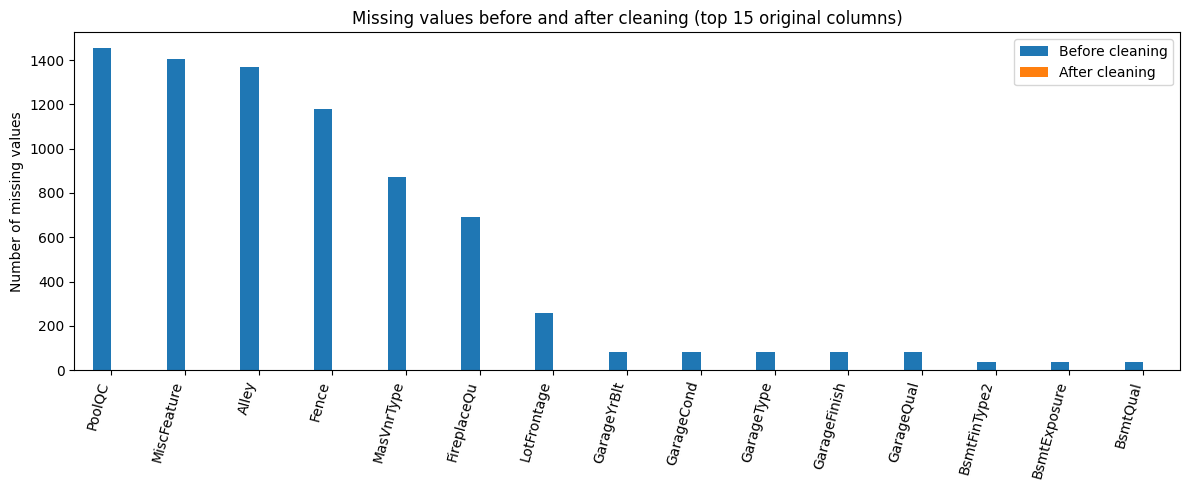

In [15]:
missing_before = df_raw.isna().sum().sort_values(ascending=False)
missing_before = missing_before[missing_before > 0].head(15)

if len(missing_before):
    missing_after = df_clean[missing_before.index].isna().sum()
    plot_df = pd.DataFrame({
        "Before cleaning": missing_before,
        "After cleaning": missing_after
    })
    plot_df.plot(kind="bar", figsize=(12, 5))
    plt.title("Missing values before and after cleaning (top 15 original columns)")
    plt.ylabel("Number of missing values")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the original dataset.")

## 3. Data Integration

Data integration combines records or attributes from different sources using a shared key. The House Prices file includes `Id`, which can be used to join a second table.
This cell builds a **teaching-only supplementary table** from a few existing columns, then merges it back using `Id`. This demonstrates the mechanics of a join; it is not independent new information and should not be used as an actual predictive improvement.

While working with realworld project, replace `supplementary` with an external file that has a valid shared identifier.

In [16]:
if "Id" not in df_clean.columns:
    print("No 'Id' column found")
    df_integrated = df_clean.copy()
else:
    available_context = [c for c in ["Id", "Neighborhood", "HouseStyle"] if c in df_clean.columns]
    supplementary = df_clean[available_context].drop_duplicates("Id").copy()

    # Rename fields to show that the joined table contributes supplementary attributes.
    rename_map = {}
    if "Neighborhood" in supplementary.columns:
        rename_map["Neighborhood"] = "Neighborhood_from_supplement"
    if "HouseStyle" in supplementary.columns:
        rename_map["HouseStyle"] = "HouseStyle_from_supplement"
    supplementary = supplementary.rename(columns=rename_map)

    df_integrated = df_clean.merge(
        supplementary,
        on="Id",
        how="left",
        validate="one_to_one"
    )

    print("Original cleaned shape:", df_clean.shape)
    print("Supplementary table shape:", supplementary.shape)
    print("Integrated shape:", df_integrated.shape)
    display(df_integrated[["Id"] + [c for c in supplementary.columns if c != "Id"]].head())

    print(
        "\nTeaching note: the supplementary columns were derived from the original table. "
        "They illustrate joining only; they do not add independent information."
    )

Original cleaned shape: (1460, 81)
Supplementary table shape: (1460, 3)
Integrated shape: (1460, 83)


,Id,Neighborhood_from_supplement,HouseStyle_from_supplement
0,1,CollgCr,2Story
1,2,Veenker,1Story
2,3,CollgCr,2Story
3,4,Crawfor,2Story
4,5,NoRidge,2Story



Teaching note: the supplementary columns were derived from the original table. They illustrate joining only; they do not add independent information.


### Integrating the external file

incase a suplimentary table is separate like example`property_extra.csv`, you can uncomment and adapt the following code. It must contain a compatible `Id` key.

In [17]:
# OPTIONAL EXAMPLE — run only if you have property_extra.csv:
#
# extra = pd.read_csv("property_extra.csv")
# if "Id" not in extra.columns:
#     raise ValueError("The supplementary file must contain an Id column.")
# df_integrated_real = df_clean.merge(
#     extra, on="Id", how="left", validate="one_to_one"
# )
# display(df_integrated_real.head())

## 4. Data Reduction

Data reduction aims to reduce the amount of data while retaining useful information. This lab demonstrates:
- removing identifier columns from predictive features;
- removing constant features; and
- selecting a limited number of numerical features using a univariate statistical score.

Feature selection is fitted using the training split only to avoid using validation outcomes during selection.

In [18]:
# Separate target and predictors. Id is an identifier, not a property measurement.
target = "SalePrice"
drop_from_features = [target]
if "Id" in df_clean.columns:
    drop_from_features.append("Id")

X = df_clean.drop(columns=drop_from_features, errors="ignore").copy()
y = df_clean[target].copy()

# Convert categorical features to one-hot encoded columns for modelling.
X_encoded = pd.get_dummies(X, drop_first=False, dummy_na=False)
X_encoded = X_encoded.replace([np.inf, -np.inf], np.nan)

# Impute any residual missing values after encoding.
X_encoded = X_encoded.fillna(X_encoded.median(numeric_only=True)).fillna(0)

print("Predictor columns before reduction:", X_encoded.shape[1])

# Remove constant columns.
variance_selector = VarianceThreshold(threshold=0.0)
X_nonconstant_array = variance_selector.fit_transform(X_encoded)
nonconstant_columns = X_encoded.columns[variance_selector.get_support()]
X_nonconstant = pd.DataFrame(
    X_nonconstant_array, columns=nonconstant_columns, index=X_encoded.index
)

print("Predictor columns after removing constant columns:", X_nonconstant.shape[1])

# Split before supervised feature selection.
X_train, X_valid, y_train, y_valid = train_test_split(
    X_nonconstant, y, test_size=0.2, random_state=42
)

k = min(20, X_train.shape[1])
selector = SelectKBest(score_func=f_regression, k=k)
X_train_selected_array = selector.fit_transform(X_train, y_train)
X_valid_selected_array = selector.transform(X_valid)
selected_features = X_train.columns[selector.get_support()]

X_train_selected = pd.DataFrame(
    X_train_selected_array, columns=selected_features, index=X_train.index
)
X_valid_selected = pd.DataFrame(
    X_valid_selected_array, columns=selected_features, index=X_valid.index
)

print(f"Selected {len(selected_features)} features out of {X_train.shape[1]}.")
display(pd.DataFrame({"selected_feature": selected_features}))

Predictor columns before reduction: 302
Predictor columns after removing constant columns: 302
Selected 20 features out of 302.


,selected_feature
0,OverallQual
1,YearBuilt
2,YearRemodAdd
3,MasVnrArea
4,TotalBsmtSF
5,1stFlrSF
6,GrLivArea
7,FullBath
8,TotRmsAbvGrd
9,Fireplaces


## 5. Data Transformation

Data transformation changes the scale or distribution of values. Here we demonstrate:
1. a log transformation of the typically right-skewed `SalePrice` variable;
2. standard scaling (mean 0, standard deviation 1); and
3. min-max scaling (values mapped to the range 0–1).

For a predictive workflow, fit scalers on training data only and apply the fitted scaler to validation data. `SalePrice` is transformed separately for demonstration.

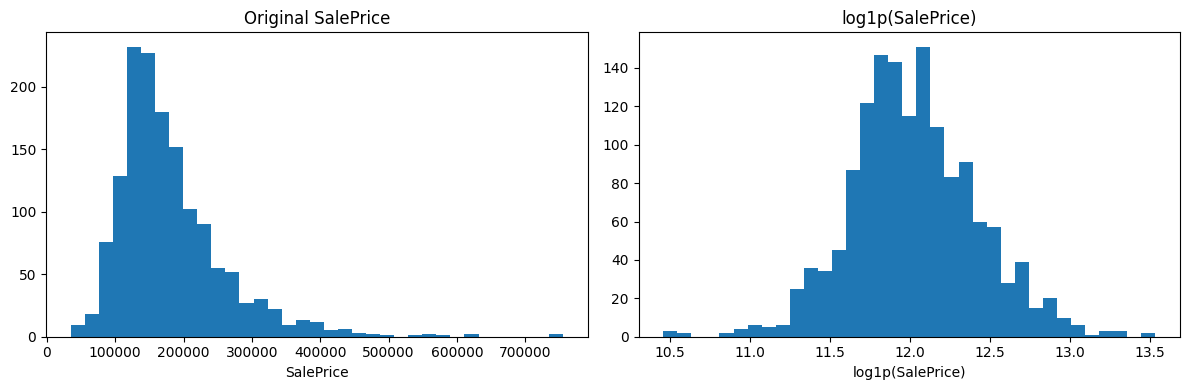

Standard-scaled training sample:


,OverallQual,YearBuilt,YearRemodAdd,MasVnrArea,TotalBsmtSF,1stFlrSF,GrLivArea,FullBath,TotRmsAbvGrd,Fireplaces,GarageCars,GarageArea,ExterQual_TA,Foundation_PConc,BsmtQual_Ex,BsmtQual_TA,HeatingQC_Ex,KitchenQual_Ex,KitchenQual_TA,FireplaceQu_None
254,-0.820445,-0.455469,-1.346063,-0.597889,0.572612,0.374235,-0.407093,-1.055566,-0.964566,-0.958592,-1.056544,-0.863837,0.778847,-0.895806,-0.300948,1.11438,-0.998289,-0.265664,0.991475,1.065497
1066,-0.088934,0.718609,0.439214,-0.597889,-0.596547,-0.958202,0.083170,0.773664,0.270755,0.592150,0.295092,-0.456264,-1.283949,1.116313,-0.300948,-0.89736,-0.998289,-0.265664,0.991475,-0.938529
638,-0.820445,-1.988293,-1.683818,-0.597889,-0.603357,-0.965964,-1.395250,-1.055566,-1.582227,-0.958592,-2.408179,-2.257169,0.778847,-0.895806,-0.300948,-0.89736,-0.998289,-0.265664,0.991475,1.065497
799,-0.820445,-1.107734,-1.683818,0.861522,-0.750921,-0.487321,0.458975,-1.055566,0.270755,2.142892,-1.056544,-1.119755,0.778847,-0.895806,-0.300948,-0.89736,1.001714,-0.265664,-1.008599,-0.938529
380,-0.820445,-1.531707,-1.683818,-0.597889,-0.081209,-0.370895,0.312087,0.773664,-0.346905,0.592150,-1.056544,-0.797488,0.778847,-0.895806,-0.300948,1.11438,-0.998289,-0.265664,-1.008599,-0.938529


Min-max-scaled training sample:


,OverallQual,YearBuilt,YearRemodAdd,MasVnrArea,TotalBsmtSF,1stFlrSF,GrLivArea,FullBath,TotRmsAbvGrd,Fireplaces,GarageCars,GarageArea,ExterQual_TA,Foundation_PConc,BsmtQual_Ex,BsmtQual_TA,HeatingQC_Ex,KitchenQual_Ex,KitchenQual_TA,FireplaceQu_None
254,0.444444,0.615942,0.116667,0.000000,0.215057,0.224874,0.184627,0.333333,0.250000,0.000000,0.25,0.207334,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
1066,0.555556,0.876812,0.733333,0.000000,0.130769,0.106700,0.233044,0.666667,0.416667,0.333333,0.50,0.267983,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
638,0.444444,0.275362,0.000000,0.000000,0.130278,0.106012,0.087038,0.333333,0.166667,0.000000,0.00,0.000000,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
799,0.444444,0.471014,0.000000,0.182874,0.119640,0.148463,0.270158,0.333333,0.416667,0.666667,0.25,0.169252,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
380,0.444444,0.376812,0.000000,0.000000,0.167921,0.158788,0.255652,0.666667,0.333333,0.333333,0.25,0.217207,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [19]:
# Compare SalePrice before and after log1p transformation.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_clean["SalePrice"], bins=35)
axes[0].set_title("Original SalePrice")
axes[0].set_xlabel("SalePrice")
axes[1].hist(np.log1p(df_clean["SalePrice"]), bins=35)
axes[1].set_title("log1p(SalePrice)")
axes[1].set_xlabel("log1p(SalePrice)")
plt.tight_layout()
plt.show()

df_transformed = df_clean.copy()
df_transformed["SalePrice_log1p"] = np.log1p(df_transformed["SalePrice"])

# Scale the selected numeric feature matrix using training-only fitting.
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X_train_standard = pd.DataFrame(
    standard_scaler.fit_transform(X_train_selected),
    columns=X_train_selected.columns,
    index=X_train_selected.index
)
X_valid_standard = pd.DataFrame(
    standard_scaler.transform(X_valid_selected),
    columns=X_valid_selected.columns,
    index=X_valid_selected.index
)

X_train_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(X_train_selected),
    columns=X_train_selected.columns,
    index=X_train_selected.index
)
X_valid_minmax = pd.DataFrame(
    minmax_scaler.transform(X_valid_selected),
    columns=X_valid_selected.columns,
    index=X_valid_selected.index
)

print("Standard-scaled training sample:")
display(X_train_standard.head())
print("Min-max-scaled training sample:")
display(X_train_minmax.head())

## 6. Data Discretization

Discretization converts continuous variables into categories or intervals. This example uses:
- equal-width bins for `GrLivArea` (above-ground living area); and
- quantile-based bins for `SalePrice`, aiming for a similar number of records in each price group.

The price categories are for exploration. When building a predictive model for `SalePrice`, do not use a category derived from `SalePrice` as an input feature because that would lead to turget leakage.

Living area bin counts:


GrLivArea_bin
Small         968
Medium        474
Large          14
Very Large      4
Name: count, dtype: int64

Sale price group counts:


SalePrice_group
Budget       365
Mid-range    367
Upper-mid    366
Premium      362
Name: count, dtype: int64

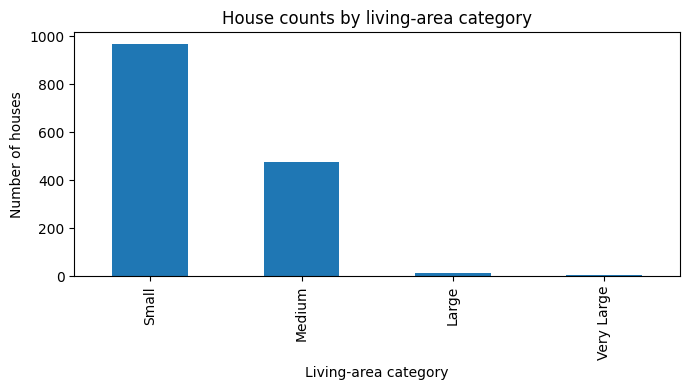

In [20]:
df_discrete = df_clean.copy()

if "GrLivArea" in df_discrete.columns:
    df_discrete["GrLivArea_bin"] = pd.cut(
        df_discrete["GrLivArea"],
        bins=4,
        labels=["Small", "Medium", "Large", "Very Large"],
        include_lowest=True
    )
    print("Living area bin counts:")
    display(df_discrete["GrLivArea_bin"].value_counts(dropna=False).sort_index())

df_discrete["SalePrice_group"] = pd.qcut(
    df_discrete["SalePrice"],
    q=4,
    labels=["Budget", "Mid-range", "Upper-mid", "Premium"],
    duplicates="drop"
)
print("Sale price group counts:")
display(df_discrete["SalePrice_group"].value_counts(dropna=False).sort_index())

if "GrLivArea_bin" in df_discrete.columns:
    df_discrete["GrLivArea_bin"].value_counts().sort_index().plot(
        kind="bar", figsize=(7, 4)
    )
    plt.title("House counts by living-area category")
    plt.xlabel("Living-area category")
    plt.ylabel("Number of houses")
    plt.tight_layout()
    plt.show()

## 7. Data Augmentation

Data augmentation creates additional useful information. This lab covers two different approaches:

**A. Feature augmentation (recommended baseline):** derive meaningful predictors such as total bathrooms, total square footage, house age, and whether a property has a second-floor area.

**B. Synthetic numerical augmentation (additional demonstration):** create small perturbations of numerical training rows only. This is a simplified teaching demonstration, not a guaranteed valid way to augment house-price data. Synthetic examples may be unrealistic, and this method should not be used in a final model without validation and domain checks.

Never augment the validation/test set. Do not use the target variable to create input features.

In [21]:
df_augmented_features = df_clean.copy()

# New property features, created only when their source columns exist.
if all(c in df_augmented_features.columns for c in ["FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath"]):
    df_augmented_features["TotalBathrooms"] = (
        df_augmented_features["FullBath"]
        + 0.5 * df_augmented_features["HalfBath"]
        + df_augmented_features["BsmtFullBath"]
        + 0.5 * df_augmented_features["BsmtHalfBath"]
    )

area_components = [
    c for c in ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF"]
    if c in df_augmented_features.columns
]
if area_components:
    df_augmented_features["TotalAreaSF"] = df_augmented_features[area_components].sum(axis=1)

if "YearBuilt" in df_augmented_features.columns:
    reference_year = int(df_augmented_features["YearBuilt"].max())
    df_augmented_features["HouseAgeAtLatestBuildYear"] = (
        reference_year - df_augmented_features["YearBuilt"]
    )

if "2ndFlrSF" in df_augmented_features.columns:
    df_augmented_features["HasSecondFloor"] = (
        df_augmented_features["2ndFlrSF"] > 0
    ).astype(int)

print("Original number of columns:", df_clean.shape[1])
print("After feature augmentation:", df_augmented_features.shape[1])
new_columns = [c for c in df_augmented_features.columns if c not in df_clean.columns]
print("New features:", new_columns)
display(df_augmented_features[new_columns + ["SalePrice"]].head())

Original number of columns: 81
After feature augmentation: 85
New features: ['TotalBathrooms', 'TotalAreaSF', 'HouseAgeAtLatestBuildYear', 'HasSecondFloor']


,TotalBathrooms,TotalAreaSF,HouseAgeAtLatestBuildYear,HasSecondFloor,SalePrice
0,3.5,2566,7,1,208500
1,2.5,2524,34,0,181500
2,3.5,2706,9,1,223500
3,2.0,2473,95,1,140000
4,3.5,3343,10,1,250000


### synthetic augmentation demonstration

This creates a small number of perturbed copies of **training predictors**. It uses numeric predictors only and does not synthesize `SalePrice`; therefore it demonstrates the mechanics of feature augmentation, not a complete synthetic labelled dataset for supervised learning. The original validation set remains untouched.

For a real regression task, use a method designed for tabular regression and validate carefully whether synthetic samples improve generalization.

In [22]:
# Use the selected numerical training matrix from the reduction section.
# Small Gaussian noise is added after standardization to avoid scale dependence.
rng = np.random.default_rng(42)
augmentation_fraction = 0.10  # create synthetic rows equal to 10% of training rows
n_synthetic = max(1, int(len(X_train_standard) * augmentation_fraction))

sample_positions = rng.integers(0, len(X_train_standard), size=n_synthetic)
base_rows = X_train_standard.iloc[sample_positions].to_numpy()
noise = rng.normal(loc=0.0, scale=0.03, size=base_rows.shape)
synthetic_X = pd.DataFrame(
    base_rows + noise,
    columns=X_train_standard.columns
)

print("Original training rows:", len(X_train_standard))
print("Synthetic predictor rows created:", len(synthetic_X))
print("Validation rows (unchanged):", len(X_valid_standard))
display(synthetic_X.head())

print(
    "\nCaution: these rows have no matching synthetic SalePrice labels. "
    "They are suitable for demonstrating augmentation mechanics only, not for "
    "directly training a supervised regression model."
)

Original training rows: 1168
Synthetic predictor rows created: 116
Validation rows (unchanged): 292


,OverallQual,YearBuilt,YearRemodAdd,MasVnrArea,TotalBsmtSF,1stFlrSF,GrLivArea,FullBath,TotRmsAbvGrd,Fireplaces,GarageCars,GarageArea,ExterQual_TA,Foundation_PConc,BsmtQual_Ex,BsmtQual_TA,HeatingQC_Ex,KitchenQual_Ex,KitchenQual_TA,FireplaceQu_None
0,-0.097188,-1.258566,-1.709793,-0.568840,-0.454065,-0.554288,-0.301106,-1.037979,-0.325568,0.615950,-1.067006,0.382926,0.804586,-0.901546,-0.339218,1.080381,-1.025873,-0.250749,0.995747,-0.917815
1,-0.101751,0.853818,0.602734,-0.607169,-0.998292,-1.451528,0.295472,0.762212,0.852541,-0.943983,0.281010,0.600958,0.793269,1.129709,-0.280986,-0.900315,-1.010988,-0.268056,-1.059219,1.022083
2,-1.591636,-1.529011,-1.671825,-0.625053,-0.864425,-0.890766,-0.391074,-1.033440,0.860407,-0.964755,-1.085045,-1.272103,0.804056,-0.947626,-0.287915,1.121512,-1.016114,-0.309046,0.993639,1.049612
3,1.381068,1.012784,0.873273,-0.605069,-1.514904,-1.004569,-0.200191,0.814440,0.295809,0.602856,0.338991,0.204739,-1.303142,1.088515,-0.312642,-0.938661,1.020768,-0.272331,-1.052723,-0.968997
4,0.651983,1.069886,0.933372,2.049288,-0.427470,-0.090110,-0.791538,0.781695,-0.371294,0.579689,0.276729,-0.185613,-1.251970,1.121024,3.318077,-0.928430,0.951473,-0.280253,-1.010212,-0.885491



Caution: these rows have no matching synthetic SalePrice labels. They are suitable for demonstrating augmentation mechanics only, not for directly training a supervised regression model.


## 8. Comparison

Use this final cell to summarize how the row and column counts changed. Some activities create separate copies rather than changing `df_clean`.

In [23]:
summary = pd.DataFrame([
    {"stage": "Original dataset", "rows": df_raw.shape[0], "columns": df_raw.shape[1]},
    {"stage": "After cleaning", "rows": df_clean.shape[0], "columns": df_clean.shape[1]},
    {"stage": "Integration teaching example", "rows": df_integrated.shape[0], "columns": df_integrated.shape[1]},
    {"stage": "After feature augmentation", "rows": df_augmented_features.shape[0], "columns": df_augmented_features.shape[1]},
    {"stage": "Encoded predictors", "rows": X_encoded.shape[0], "columns": X_encoded.shape[1]},
    {"stage": "After constant-feature removal", "rows": X_nonconstant.shape[0], "columns": X_nonconstant.shape[1]},
    {"stage": "After feature selection", "rows": X_train_selected.shape[0], "columns": X_train_selected.shape[1]},
])
display(summary)

print("Notebook workflow completed.")

,stage,rows,columns
0,Original dataset,1460,81
1,After cleaning,1460,81
2,Integration teaching example,1460,83
3,After feature augmentation,1460,85
4,Encoded predictors,1460,302
5,After constant-feature removal,1460,302
6,After feature selection,1168,20


Notebook workflow completed.


# Review
## Make a grouped discussion to answer the following questions
1. Why should the original dataset be preserved before cleaning?
2. What is the difference between a missing value and a value that indicates a feature is absent?
3. Why is a shared key required for data integration?
4. How can removing irrelevant features improve efficiency or reduce overfitting?
5. Compare standard scaling, min-max scaling, and log transformation.
6. What is the difference between equal-width and quantile-based discretization?
7. Explain the difference between feature engineering and synthetic data augmentation.
8. Why should transformations and feature selection be fitted using training data only?
9. Why must the validation dataset remain separate from augmentation?
10. Which preprocessing steps would you retain for a real `SalePrice` prediction project, and why?